<a href="https://colab.research.google.com/github/johnryantaylor/QCES/blob/main/Project4_storms.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Set environment variables for best performance
%env OMP_NUM_THREADS=1
%env NUMEXPR_MAX_THREADS=1

# Minimize logging output
import logging
logging.disable(logging.DEBUG)

env: OMP_NUM_THREADS=1
env: NUMEXPR_MAX_THREADS=1


# Project 4: Storms
In this project, we will use Dedalus to solve the 2-layer quasi-geostrophic equations to model the development of atmospheric storm systems.

The two-layer quasi-geostrophic (QG) equations describe the motion of two vertically-stacked shallow layers of fluid in the limit where the Rossby number, $Ro=U/fL$ is small, where $U$ is a characteristic velocity scale, $L$ is a characteristic horizontal lengthscale, and $f$ is the Coriolis parameter. Here, we will use `1` to refer to quantitites in the upper layer and `2` to refer to quantities in the lower layer.

The fluid in the upper layer is lighter than the fluid in the lower layer (with $\rho_1<\rho_2$). When the interface separating the upper and lower layers isn't flat, the varying thicknesses of the upper and lower layers implies that there are horizontal gradients in the hydrostatic pressure. When the Rossby number is small, $Ro\ll 1$, the flow will tend to be close to geostrophic balance a velocity difference between the upper and lower layer that balances the horizontal pressure gradients.

Student tasks are in [Section 1.5](#section1pt5), [Section 2.3](#section2pt3), and [Section 3.2](#section3pt2).

## 1. Two-layer quasi-geostrophic equations in a periodic box

In this section we will solve a non-dimensional version of the two-layer QG equations in Cartesian coordinates. Let $+x$ denote the eastwards direction and $+y$ denote the northwards direction. We start with a flow in geostrophic balance where the velocity is constant in each layer. Let $U \hat{\mathbf{x}}$ denote the velocity in the top layer and $-U \hat{\mathbf{x}}$ denote the velocity in the bottom layer. Geostrophic balance then implies that the interface has a constant, non-zero slope. We will invoke the so-called "beta-plane" approximation and make the Coriolis parameter a linear function of $y$. 

In this section we solve for the departures to the background state described above. We let $q_1$ and $q_2$ denote the perturbation QG potential vorticity and $\psi_1$ and $\psi_2$ denote the perturbation streamfunction. Although the background state is not periodic, we apply periodic boundary conditions in $x$ and $y$ to the perturbation quantities. This has the effect of maintaining the north/south potential vorticity gradient associated with the background state.

### 1.1 Governing equations

The script below solves the following equations:

$$ \partial_t(q_1) + U \partial_x(q_1) + \frac{2U}{R_{d1}^2}\partial_x(\psi_1)-\nu \nabla^2 q_1 = - J(\psi_1, q_1), $$

$$ \partial_t(q_2) - U \partial_x(q_2) - \frac{2U}{R_{d2}^2}\partial_x(\psi_2)-\nu \nabla^2 q_2 = - J(\psi_2, q_2), $$

where $R_{d1,2}=\sqrt{g'H_{1,2}}/f_0$ is the internal deformation radius in each layer, $g'=(\rho_2-\rho_1)/\rho_0$ is the reduced gravity, $\rho_0$ is a reference density, $J(a,b)=\partial_x(a)\partial_y(b) - \partial_y(a)\partial_x(b)$ is the Jacobian operator and $\nu$ is a viscosity which is added to keep the model stable.

In addition to the equations above, two other equations relate the perturbation potential vorticity and streamfunctions:

$$q_1=\nabla^2\psi_1 - \frac{\psi_1-\psi_2}{R_{d1}^2}, $$
$$q_2=\nabla^2\psi_2 + \frac{\psi_1-\psi_2}{R_{d2}^2}. $$

### 1.2 Tau method

The equations above are invariant to a constant added to $\psi_1-\psi_2$. Therefore, there are infinitely many solutions to the above equations and the coefficient matrix associated with the discretized equations will be singular. To avoid this, we can add an extra equation to the system to set this constant offset. Here, we do this by including the following equation:

$$ \int\int \psi_1 dxdy = 0 $$

which in effect ensures that the spatial mean of $\psi_1$ is zero. The problem now is that we have five equations for four unknowns. One fix is to include another unknown in our system. We will include a constant called $\tau_{\psi1}$ and we will add it to the equation relating the upper layer QG potential voricity and streamfunction which then becomes:

$$q_1=\nabla^2\psi_1 - \frac{\psi_1-\psi_2}{R_{d1}^2} + \tau_{\psi1}. $$

Since adding a constant to the potential vorticity and streamfunction doesn't have any impact on the dynamics of the system, adding $\tau_{\psi1}$ here won't cause any problems and we now have a fully constained set of equations.


### 1.3 Dedalus script

The script below solves the 2-layer QG equations given above with non-dimensional parameters. Note that the velocity gets faster as the simulation progresses. The script uses an adaptive timestep, which is reduced as the velocity increases so that the CFL criterion is satisfied. If you find that the code blows up (returns NaNs and a white screen), try reducing `max_timestep` or the `safety` factor.

In [2]:
# # Code to solve the two-layer shallow water quasi-geostrophic equations

# Import the required packages
import numpy as np
import dedalus.public as dedalus
import logging
import matplotlib.pyplot as plt

logger = logging.getLogger(__name__)

# Set the non-dimensional parameters
Nx = 64 # Number of gridpoints in x
Ny = 64 # Number of gridpoints in y
Lx = 100 # Domain size in x
Ly = 100 # Domain size in y
Rd1 = 3 # Deformation radius in layer 1
Rd2 = 3 # Deformation radius in layer 2
U = 1 # Background velocity in layer 1

#Set the hypervisocisty based on the grid spacing
delx = Lx/Nx
nu = 0.2

# Set the maximum timestep and the time interval between saved outputs
# The timestep is adjusted during the simulation based on the CFL criterion (see below)
max_timestep = 0.25
save_dt = 0.5
stop_sim_time = 70

# Bases
coords = dedalus.CartesianCoordinates('x', 'y')
dist = dedalus.Distributor(coords, dtype=np.float64)
xbasis = dedalus.RealFourier(coords['x'], size=Nx, bounds=(0, Lx), dealias=3/2)
ybasis = dedalus.RealFourier(coords['y'], size=Ny, bounds=(0, Ly), dealias=3/2)

# Define the coordinates
x, y = dist.local_grids(xbasis, ybasis)

# Define the fields
# Here psi is the streamfunction and q is the QG potential vorticity
# "1" corresponds to the upper layer and "2" corresponds to the lower layer
psi1 = dist.Field(name='psi1', bases=(xbasis, ybasis))
psi2 = dist.Field(name='psi2', bases=(xbasis, ybasis))
q1 = dist.Field(name='q1', bases=(xbasis, ybasis))
q2 = dist.Field(name='q2', bases=(xbasis, ybasis))
tau_psi1 = dist.Field(name='tau_psi1')

# Set the initial conditions
q1.fill_random('g', seed=42, distribution='normal', scale=1e-3) # Random noise
q2.fill_random('g', seed=42, distribution='normal', scale=1e-3) # Random noise

# Define the operators that will be used to write the equations
dx = lambda A: dedalus.Differentiate(A, coords['x'])
dy = lambda A: dedalus.Differentiate(A, coords['y'])
lap = lambda A: dedalus.Laplacian(A)
J = lambda A, B: dx(A)*dy(B)-dy(A)*dx(B)
integ = lambda A: dedalus.Integrate(A, ('x', 'y'))

# Define problem
problem = dedalus.IVP([q1, q2, psi1, psi2, tau_psi1], namespace=locals())

# First, add the two equations for the evolution of the QG potential vorticity
problem.add_equation("dt(q1) + U*dx(q1) + (2*U/Rd1**2.0)*dx(psi1) - nu*lap(q1) = - dx(psi1)*dy(q1) + dy(psi1)*dx(q1)")
problem.add_equation("dt(q2) - U*dx(q2) - (2*U/Rd2**2.0)*dx(psi2) - nu*lap(q2) = - dx(psi2)*dy(q2) + dy(psi2)*dx(q2)")

problem.add_equation("lap(psi1)-(psi1-psi2)/(Rd1**2.0)+tau_psi1=q1")
problem.add_equation("lap(psi2)+(psi1-psi2)/(Rd2**2.0)=q2")

problem.add_equation("integ(psi1) = 0")

# Now, set the solver
solver = problem.build_solver(dedalus.RK443)
solver.stop_sim_time = stop_sim_time

# Set up an adaptive timestep based on the CFL criterion using the perturbation velocity in each layer
# Advection by the background velocity, U, is treated implicitly, so it doesn't limit the timestep
ex, ey = coords.unit_vector_fields(dist)
CFL = dedalus.CFL(solver, initial_dt=max_timestep, cadence=10, safety=0.5, threshold=0.05, max_change=1.5, min_change=0.5, max_dt=max_timestep)
CFL.add_velocity(-dy(psi1)*ex + dx(psi1)*ey)
CFL.add_velocity(-dy(psi2)*ex + dx(psi2)*ey)

psi1.change_scales(1)
psi2.change_scales(1)
q1.change_scales(1)
q2.change_scales(1)
psi1_save = [np.copy(psi1['g'])]; 
psi2_save = [np.copy(psi2['g'])]; 
q1_save = [np.copy(q1['g'])]; 
q2_save = [np.copy(q2['g'])]; 
t_save = [solver.sim_time]; # Save the initial condition and the initial time
# Main loop
try:
    logger.info('Starting main loop')
    while solver.proceed:
        timestep = CFL.compute_timestep()
        solver.step(timestep)
        if solver.sim_time >= len(t_save)*save_dt: # Save the output every save_dt time units
            logger.info('Iteration=%i, Time=%e, dt=%e' %(solver.iteration, solver.sim_time, timestep))
            psi1.change_scales(1)
            psi2.change_scales(1)
            psi1_save.append(np.copy(psi1['g']))
            psi2_save.append(np.copy(psi2['g']))
            q1.change_scales(1)
            q2.change_scales(1)
            q1_save.append(np.copy(q1['g']))
            q2_save.append(np.copy(q2['g']))
            t_save.append(solver.sim_time)
except:
    logger.error('Exception raised, triggering end of main loop.')
    raise
finally:
    solver.log_stats()

# Convert the variables to numpy arrays for allow array slicing
psi1_save = np.array(psi1_save)
psi2_save = np.array(psi2_save)
q1_save = np.array(q1_save)
q2_save = np.array(q2_save)

2026-11-27 19:51:29,469 subsystems 0/1 INFO :: Building subproblem matrices 1/32 (~3%) Elapsed: 0s, Remaining: 1s, Rate: 4.7e+01/s
2026-11-27 19:51:29,537 subsystems 0/1 INFO :: Building subproblem matrices 4/32 (~12%) Elapsed: 0s, Remaining: 1s, Rate: 4.4e+01/s
2026-11-27 19:51:29,616 subsystems 0/1 INFO :: Building subproblem matrices 8/32 (~25%) Elapsed: 0s, Remaining: 1s, Rate: 4.7e+01/s
2026-11-27 19:51:29,695 subsystems 0/1 INFO :: Building subproblem matrices 12/32 (~38%) Elapsed: 0s, Remaining: 0s, Rate: 4.8e+01/s
2026-11-27 19:51:29,777 subsystems 0/1 INFO :: Building subproblem matrices 16/32 (~50%) Elapsed: 0s, Remaining: 0s, Rate: 4.9e+01/s
2026-11-27 19:51:29,860 subsystems 0/1 INFO :: Building subproblem matrices 20/32 (~62%) Elapsed: 0s, Remaining: 0s, Rate: 4.8e+01/s
2026-11-27 19:51:29,967 subsystems 0/1 INFO :: Building subproblem matrices 24/32 (~75%) Elapsed: 1s, Remaining: 0s, Rate: 4.6e+01/s
2026-11-27 19:51:30,052 subsystems 0/1 INFO :: Building subproblem matric

### 1.4 Visualization
The script below will make a movie showing the evolution of $\psi_2-\psi_1$, which is proportional to the displacement of the interior interface.

2026-11-27 19:51:59,357 matplotlib.animation 0/1 INFO :: Animation.save using <class 'matplotlib.animation.FFMpegWriter'>
2026-11-27 19:51:59,358 matplotlib.animation 0/1 INFO :: MovieWriter._run: running command: /home/ealish/miniforge3/bin/ffmpeg -f rawvideo -vcodec rawvideo -s 600x600 -pix_fmt rgba -framerate 25.0 -i pipe: -vcodec h264 -pix_fmt yuv420p -y /tmp/tmpbbmhbwcg/temp.m4v


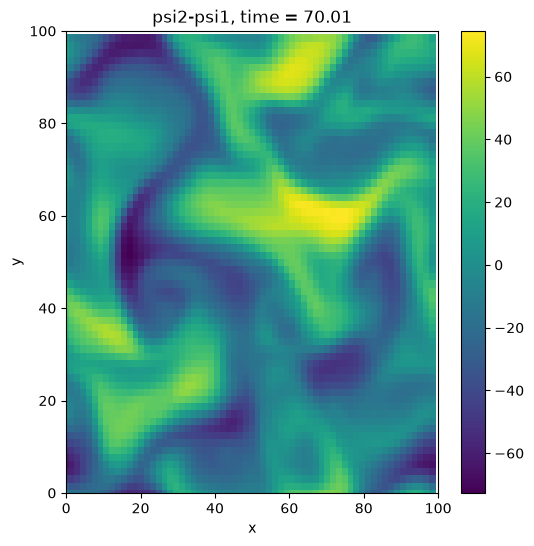

In [3]:
# create a figure and axes
fig = plt.figure(figsize=(6,6))

# Create arrays with the latitude and longitude coordinates for plotting using pcolor
from dedalus.extras import plot_tools
(X, Y) = plot_tools.quad_mesh(np.squeeze(x), np.squeeze(y))  

# Define an animation function
def drawframe(n):
    plt.clf()
    streamfunction = plt.pcolor(X, Y, (psi2_save[n,:,:].T-psi1_save[n,:,:].T))
    # Specify the axis limits and labels
    plt.xlim(0, Lx)   
    plt.ylim(0, Ly)  
    plt.colorbar()      
    plt.xlabel('x')
    plt.ylabel('y')
    plt.title('psi2-psi1, time = {0:.2f}'.format(t_save[n]))
    return (streamfunction,)

import matplotlib as mpl
mpl.rcParams['animation.ffmpeg_path'] = '/home/ealish/miniforge3/bin/ffmpeg'
from matplotlib import animation
# blit=True re-draws only the parts that have changed.
# Skip the first frame (time=0), since psi1 and psi2 are only calculated after the first timestep
anim = animation.FuncAnimation(fig, drawframe, frames=range(1, len(t_save)), interval=40, blit=True)

from IPython.display import HTML
HTML(anim.to_html5_video())

### 1.5 Student investigation
<a id='section1pt5'></a>
In lectures, we found growing solutions of the form
 
$$ \psi_{1,2}=Re\left[\hat{\psi}_{1,2}e^{ikx+\sigma t}\right], $$

where

$$ \sigma = Uk \left(\frac{2/R_d^2-k^2}{2/R_d^2+k^2}\right)^{1/2}, $$

is the exponential growth rate, $R_d=\sqrt{g'H}/f_0$ is the deformation radius in each layer, and $k$ is the wavenumber in the $x$ direction where $\lambda=2\pi/k$ is the wavelength.

In the box below, compare the result of the simulation with what you would expect based on the growth rate given above. Comment on the possible reasons for any differences. Discuss the behaviour of the flow in the simulation at later times and comment on the relevance to storms in the atmosphere.

INSERT COMMENTS HERE, ~ 1 PARAGRAPH WITH OPTIONAL PLOT(S)

## 2. The jet stream and baroclinic instability on a sphere

The configuration in the previous section illustrates baroclinic instability, but the setup is quite idealized. In particular, we assumed that the Coriolis parameter and the initial velocity were constant. In the atmosphere there are strong winds at the top of the troposphere in a band called the jet stream. The jet stream is several hundred kilometers wide with wind speeds that can exceed 100 miles per hour (roughly 50 m/s). A variable Coriolis parameter is important for constraining the jet dynamics. Here, we will solve the QG equations on a sphere, where the Coriolis parameter is $f=2\Omega \sin(\text{latitude})$. Rather than splitting the flow into a background state and perturbations as we did in Section 1, we now solve for the full QG potential vorticity in each layer. The equations for $q_1$ and $q_2$ become:

$$ \partial_t(q_1) + \nu_4 \nabla^4 q_1 = - J(\psi_1, q_1 + f), $$

$$ \partial_t(q_2) + \nu_4 \nabla^4 q_2 = - J(\psi_2, q_2 + f), $$

where the Jacobian is now written in vector form as $J(a,b)=(\hat{\mathbf{z}}\times\nabla a)\cdot\nabla b$, and $\mathbf{u}=\hat{\mathbf{z}}\times\nabla\psi$ is the velocity in each layer.

Here, we have also switched from a viscous term to a 'hyperviscous' term, where $-\nabla^2 q_{1,2}$ has been replaced by $\nabla^4 q_{1,2}$ where $\nabla^4=(\nabla^2)^2$. Using a hyperviscosity is useful because it acts to preferentially damp small scale motions (with large horizontal wavenumbers), while having less influence on the larger scale motions (with small horizontal wavenumbers). It is useful in this case since we would like the jet not to be strongly influenced by viscosity.

We can represent mid-latitude jet streams by localizing the north/south gradient in the QG potential voriticty in a narrow band of latitude. Let the initial condition for potential vorticity in each layer be:

$$ q_{1,2} = \pm Q_{1,2} \left[tanh\left(\frac{lat-lat_0}{w}\right) + tanh\left(\frac{lat+lat_0}{w}\right)\right],$$

where $lat_0$ is the latitude of the centers of the jets, $w$ is the jet width (in radians), and $Q_{1,2}=\Delta U R w/R_{d1,2}^2$ are constant dimensional amplitudes. Here $\Delta U$ is the maximum difference between the upper and lower layer velocities in the jets and $R$ is the radius of the Earth, so that $Rw$ is the width of the jet in km. The amplitudes come from thermal wind balance: when the jet is wider than the deformation radius, the relative vorticity is small compared with the other terms, so that $q_1\approx-(\psi_1-\psi_2)/R_{d1}^2$ and $\partial_y q_1 \approx (u_1-u_2)/R_{d1}^2$. Note that the potential vorticity increases northwards across both jets, so that both jets are westerly (eastward) in the upper layer, as in the atmosphere. 

### 2.1 Dedalus script

The script below sets up and solves the 2-layer QG equations on a sphere with the radius of the Earth, using dimensional units (kilometers for distance and seconds for time). As in the shallow water example in Project 3, the independent variables are the longitude, $\phi$, and the colatitude, $\theta$. The jets are centered at 45ºN and 45ºS. Note that we use a constant deformation radius in each layer, which is an approximation since $R_d$ depends on $f$. The QG approximation also breaks down near the Equator where $f\rightarrow 0$.

Run the script below and comment on the results and the behavior of the jet stream in the text box below the script. You can also try changing some of the parameters at the top of the script to see how the result change.

As in Section 1, the script uses an adaptive timestep based on the CFL criterion. If you find that the code blows up (returns NaNs and a white screen), try reducing `max_timestep` or the `safety` factor.

Note that the script will likely take a few minutes to run.  Coordinate with the other members of your group so that you can each run a different case.

In [4]:
# Code to solve the two-layer quasi-geostrophic equations on a sphere

# Import the required packages
import numpy as np
import dedalus.public as dedalus
import logging
import matplotlib.pyplot as plt

logger = logging.getLogger(__name__)

# Set the dimensional parameters
Nphi = 128 # Number of gridpoints in phi (longitude)
Ntheta = 64 # Number of gridpoints in theta (colatitude)
R = 6.371e3 # Radius of the Earth in km
Omega = 7.29e-5 # Earth's angular velocity in radians per second
Rd1 = 500 # Deformation radius in layer 1 in km
Rd2 = 500 # Deformation radius in layer 2 in km
dU = 40/1000 # Maximum difference between the upper and lower layer velocities in the jets in km/s
lat0 = 45*np.pi/180 # Latitude of the center of the jets in radians
jet_width = 10*np.pi/180 # Width of the jet in radians

#Set the hypervisocisty based on the grid spacing
delx = 2*np.pi*R/Nphi
nu4 = 1e-6*delx**4

# Set the initial and maximum timesteps and the time interval between saved outputs
# The timestep is adjusted during the simulation based on the CFL criterion (see below)
initial_timestep = 600 # Initial timestep in seconds
max_timestep = 3600 # Maximum timestep in seconds
save_dt = 4*3600 # Time interval between saved outputs in seconds
stop_sim_time = 2e6
timestepper = dedalus.RK443

# Bases
coords = dedalus.S2Coordinates('phi', 'theta')
dist = dedalus.Distributor(coords, dtype=np.float64)
basis = dedalus.SphereBasis(coords, (Nphi, Ntheta), radius=R, dealias=3/2, dtype=np.float64)

# Define the coordinates
phi, theta = dist.local_grids(basis) # Longitude and colatitude in radians
lat = np.pi/2 - theta # Latitude in radians

# Define the fields
# Here psi is the streamfunction and q is the QG potential vorticity
# "1" corresponds to the upper layer and "2" corresponds to the lower layer
psi1 = dist.Field(name='psi1', bases=basis)
psi2 = dist.Field(name='psi2', bases=basis)
q1 = dist.Field(name='q1', bases=basis)
q2 = dist.Field(name='q2', bases=basis)
u1 = dist.VectorField(coords, name='u1', bases=basis) # Upper layer velocity vector
tau_psi1 = dist.Field(name='tau_psi1')

# Coriolis parameter, f = 2*Omega*sin(latitude)
f = dist.Field(name='f', bases=basis)
f['g'] = 2*Omega*np.cos(theta)

# Create functions to use for the initial conditions and forcing
# Here, q1_ic and q2_ic are the QG potential vorticity associated with the jets (not including f)
# The potential vorticity increases northwards across both jets, which makes both jets westerly
q1_ic = dist.Field(name='q1_ic', bases=basis)
q2_ic = dist.Field(name='q2_ic', bases=basis)
q1_ic['g'] = (dU*R*jet_width/Rd1**2.0) * (np.tanh((lat-lat0)/jet_width) + np.tanh((lat+lat0)/jet_width))
q2_ic['g'] = -(dU*R*jet_width/Rd2**2.0) * (np.tanh((lat-lat0)/jet_width) + np.tanh((lat+lat0)/jet_width))

# Set the initial conditions
q1['g'] = q1_ic['g']
q2['g'] = q2_ic['g']
# Now, add some random noise
q1p = dist.Field(name='q1', bases=basis)
q2p = dist.Field(name='q2', bases=basis)
q1p.fill_random('g', seed=42, distribution='normal', scale=1e-6) # Random noise
q2p.fill_random('g', seed=42, distribution='normal', scale=1e-6) # Random noise
q1['g'] += q1p['g']
q2['g'] += q2p['g']

# Define the operators that will be used to write the equations
# The "skew" operator rotates a vector by 90 degrees, so that skew(grad(A)) = z x grad(A)
# Dedalus can't integrate over a SphereBasis, so we constrain the average of psi1 instead
lap = lambda A: dedalus.Laplacian(A)
J = lambda A, B: dedalus.skew(dedalus.grad(A))@dedalus.grad(B)
ave = lambda A: dedalus.Average(A, coords)
del4 = lambda A: lap(lap(A))

# Define problem
problem = dedalus.IVP([q1, q2, psi1, psi2, tau_psi1], namespace=locals())
# Define Laplacian and Jacobian operators (to make equations easier to read)

# Define problem
problem = dedalus.IVP([q1, q2, psi1, psi2, u1, tau_psi1], namespace=locals())

# First, add the two equations for the evolution of the QG potential vorticity
# The advection of f by the flow (the "beta effect") is included on the right hand side
problem.add_equation("dt(q1) + nu4*del4(q1) = - J(psi1, q1 + f)")
problem.add_equation("dt(q2) + nu4*del4(q2) = - J(psi2, q2 + f)")
problem.add_equation("lap(psi1)-(psi1-psi2)/(Rd1**2.0)+tau_psi1=q1")
problem.add_equation("lap(psi2)+(psi1-psi2)/(Rd2**2.0)=q2")

problem.add_equation("u1 = skew(grad(psi1))")

problem.add_equation("ave(psi1) = 0")

# Now, set the solver
solver = problem.build_solver(timestepper)
solver.stop_sim_time = stop_sim_time

# Set up an adaptive timestep based on the CFL criterion using the velocity in each layer
CFL = dedalus.CFL(solver, initial_dt=initial_timestep, cadence=10, safety=2, threshold=0.05, max_change=1.5, min_change=0.5, max_dt=max_timestep)
CFL.add_velocity(u1)
CFL.add_velocity(dedalus.skew(dedalus.grad(psi2)))

psi1.change_scales(1)
psi2.change_scales(1)
q1.change_scales(1)
q2.change_scales(1)
psi1_save = [np.copy(psi1['g'])]; 
psi2_save = [np.copy(psi2['g'])]; 
q1_save = [np.copy(q1['g'])]; 
q2_save = [np.copy(q2['g'])]; 

# Save the upper layer velocity for later plotting and analysis
# u1['g'][0] is the eastward velocity and u1['g'][1] is the southward velocity (theta increases towards the South Pole)
u1.change_scales(1)
u1_save = [np.copy(u1['g'][0])]
v1_save = [-np.copy(u1['g'][1])]

t_save = [solver.sim_time]; # Save the initial condition and the initial time
# Main loop
try:
    logger.info('Starting main loop')
    while solver.proceed:
        timestep = CFL.compute_timestep()
        solver.step(timestep)
        if solver.sim_time >= len(t_save)*save_dt: # Save the output every save_dt seconds
            logger.info('Iteration=%i, Time=%e, dt=%e' %(solver.iteration, solver.sim_time, timestep))
            psi1.change_scales(1)
            psi2.change_scales(1)
            psi1_save.append(np.copy(psi1['g']))
            psi2_save.append(np.copy(psi2['g']))
            q1.change_scales(1)
            q2.change_scales(1)
            q1_save.append(np.copy(q1['g']))
            q2_save.append(np.copy(q2['g']))

            u1.change_scales(1)
            u1_save.append(np.copy(u1['g'][0]))
            v1_save.append(-np.copy(u1['g'][1]))

            t_save.append(solver.sim_time)
except:
    logger.error('Exception raised, triggering end of main loop.')
    raise
finally:
    solver.log_stats()

# Convert the variables to numpy arrays for allow array slicing
psi1_save = np.array(psi1_save)
psi2_save = np.array(psi2_save)
q1_save = np.array(q1_save)
q2_save = np.array(q2_save)
u1_save = np.array(u1_save)
v1_save = np.array(v1_save)


2026-11-27 19:52:55,546 subsystems 0/1 INFO :: Building subproblem matrices 1/63 (~2%) Elapsed: 0s, Remaining: 1s, Rate: 4.4e+01/s
2026-11-27 19:52:55,623 subsystems 0/1 INFO :: Building subproblem matrices 7/63 (~11%) Elapsed: 0s, Remaining: 1s, Rate: 7.1e+01/s
2026-11-27 19:52:55,699 subsystems 0/1 INFO :: Building subproblem matrices 14/63 (~22%) Elapsed: 0s, Remaining: 1s, Rate: 8.0e+01/s
2026-11-27 19:52:55,787 subsystems 0/1 INFO :: Building subproblem matrices 21/63 (~33%) Elapsed: 0s, Remaining: 1s, Rate: 8.0e+01/s
2026-11-27 19:52:55,868 subsystems 0/1 INFO :: Building subproblem matrices 28/63 (~44%) Elapsed: 0s, Remaining: 0s, Rate: 8.1e+01/s
2026-11-27 19:52:55,949 subsystems 0/1 INFO :: Building subproblem matrices 35/63 (~56%) Elapsed: 0s, Remaining: 0s, Rate: 8.2e+01/s
2026-11-27 19:52:56,035 subsystems 0/1 INFO :: Building subproblem matrices 42/63 (~67%) Elapsed: 1s, Remaining: 0s, Rate: 8.2e+01/s
2026-11-27 19:52:56,114 subsystems 0/1 INFO :: Building subproblem matri

### 2.2 Visualization

The script below plots the results and create a movie showing the upper layer wind speed (the magnitude of the velocity vector (u1, v1)). The left panel shows the sphere viewed from above the North Pole, and the right panel shows the sphere viewed from above the Equator. The white lines show latitude and longitude every 30º.

2026-11-27 19:54:49,878 matplotlib.animation 0/1 INFO :: Animation.save using <class 'matplotlib.animation.FFMpegWriter'>
2026-11-27 19:54:49,879 matplotlib.animation 0/1 INFO :: MovieWriter._run: running command: /home/ealish/miniforge3/bin/ffmpeg -f rawvideo -vcodec rawvideo -s 1200x600 -pix_fmt rgba -framerate 25.0 -i pipe: -vcodec h264 -pix_fmt yuv420p -y /tmp/tmppoj9dbxr/temp.m4v


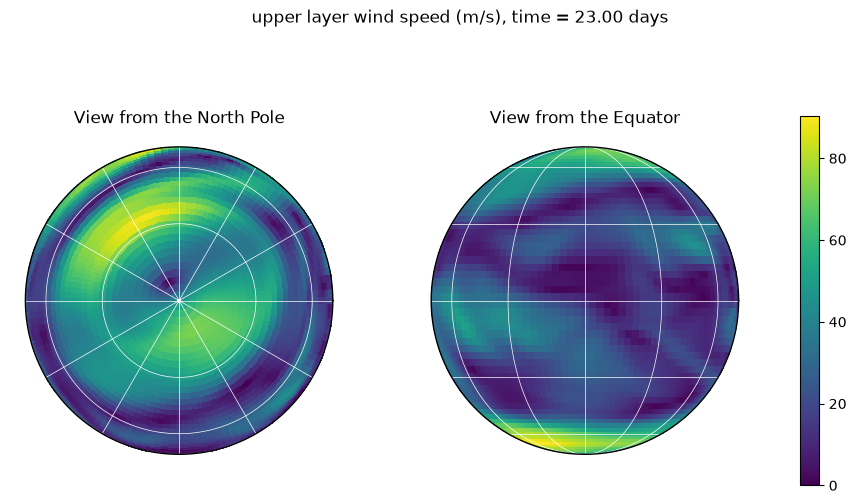

In [5]:
# Create a movie of the results

# Create a figure
fig = plt.figure(figsize=(12,6))

# Create arrays with the longitude and latitude of the corners of each grid cell (in radians) for plotting using pcolormesh
from dedalus.extras import plot_tools
(lon_mesh, lat_mesh) = plot_tools.quad_mesh(np.squeeze(phi), np.squeeze(lat))
lat_mesh = np.clip(lat_mesh, -np.pi/2, np.pi/2)

# Orthographic projection of the sphere, viewed from above the point (lon_c, lat_c)
# cos_c is negative for points on the far side of the sphere, which are hidden from view
def project(lon, lat, lon_c, lat_c):
    X = np.cos(lat)*np.sin(lon-lon_c)
    Y = np.cos(lat_c)*np.sin(lat) - np.sin(lat_c)*np.cos(lat)*np.cos(lon-lon_c)
    cos_c = np.sin(lat_c)*np.sin(lat) + np.cos(lat_c)*np.cos(lat)*np.cos(lon-lon_c)
    return X, Y, cos_c

# Set up the two views: from above the North Pole (left) and from above the Equator (right)
views = []
for (lon_c, lat_c, title) in [(0, np.pi/2, 'View from the North Pole'), (0, 0, 'View from the Equator')]:
    X, Y, cos_c = project(lon_mesh, lat_mesh, lon_c, lat_c)
    hidden = project(phi.T, lat.T, lon_c, lat_c)[2] < 0 # Grid cells on the far side of the sphere
    views.append((lon_c, lat_c, title, X, Y, hidden))

# Draw lines of latitude and longitude every 30 degrees
def draw_gridlines(lon_c, lat_c):
    lon_line = np.linspace(0, 2*np.pi, 361)
    lat_line = np.linspace(-np.pi/2, np.pi/2, 181)
    for lat_g in np.arange(-60, 61, 30)*np.pi/180:
        Xg, Yg, cos_c = project(lon_line, lat_g, lon_c, lat_c)
        plt.plot(np.where(cos_c >= 0, Xg, np.nan), Yg, color='w', lw=0.5)
    for lon_g in np.arange(0, 360, 30)*np.pi/180:
        Xg, Yg, cos_c = project(lon_g, lat_line, lon_c, lat_c)
        plt.plot(np.where(cos_c >= 0, Xg, np.nan), Yg, color='w', lw=0.5)
    plt.plot(np.cos(lon_line), np.sin(lon_line), color='k', lw=1) # Outline of the sphere

# Define an animation function
def drawframe(n):
    plt.clf()
    speed = np.sqrt(np.square(u1_save[n,:,:].T)+np.square(v1_save[n,:,:].T))*1000
    axes = []
    for i, (lon_c, lat_c, title, X, Y, hidden) in enumerate(views):
        axes.append(plt.subplot(1, 2, i+1))
        wind_speed = plt.pcolormesh(X, Y, np.ma.masked_where(hidden, speed), vmin=0, vmax=speed.max())
        draw_gridlines(lon_c, lat_c)
        plt.gca().set_aspect('equal')
        plt.axis('off')
        plt.title(title)
    plt.colorbar(wind_speed, ax=axes, shrink=0.8)
    plt.suptitle('upper layer wind speed (m/s), time = {0:.2f} days'.format(t_save[n]/3600/24))
    return (wind_speed,)

import matplotlib as mpl
mpl.rcParams['animation.ffmpeg_path'] = '/home/ealish/miniforge3/bin/ffmpeg'
from matplotlib import animation
# blit=True re-draws only the parts that have changed.
# Skip the first frame (time=0), since the velocity is only calculated after the first timestep
anim = animation.FuncAnimation(fig, drawframe, frames=range(1, len(t_save)), interval=40, blit=True)

from IPython.display import HTML
HTML(anim.to_html5_video())

### 2.3 Student investigation
<a id='section2pt3'></a>
Describe the results in the box below. To what extent are the results qualitatively different from what you saw using the previous script? Comment on the interaction between the jet and the storms. Which features in the simulation do you think occur in the atmosphere? Do you see any features in the simulation that you think are unrealistic? If so, explain why you think those features are unrealistic. 

ADD COMMENTS HERE (1-2 PARAGRAPHS). NO NEED FOR PLOTS, BUT YOU CAN INCLUDE THEM IF YOU WANT.

# 3. Forced QG flow and climate change

In the atmosphere, differential heating between the equator and poles maintains a north/south temperature gradient. In the simulations in Section 2, the storms released the energy stored in the temperature gradient and nothing replenished it. Here, we will add forcing terms that represent radiative heating and cooling, and use the model to ask how the mid-latitude jets and storms respond to changes in the equator to pole temperature difference caused by climate change.

### Temperature in the 2-layer model

In the 2-layer model, the temperature is represented by the thickness of the layers. A warm column of air has a thick upper layer, and a cold column has a thick lower layer. Through thermal wind balance, the north/south temperature gradient is related to the vertical shear:

$$ U_1-U_2 = -\frac{gH}{f_0 T_0}\frac{\partial T}{\partial y}, $$

where $H$ is the vertical distance between the centers of the two layers and $T_0$ is a reference temperature. Since $U_1-U_2=-\partial_y(\psi_1-\psi_2)$, the difference between the upper and lower layer streamfunctions is proportional to the temperature, $\psi_1-\psi_2 = gHT/(f_0 T_0)$.

### Forcing terms

We will represent radiative heating and cooling by relaxing $\psi_1-\psi_2$ towards a radiative equilibrium profile, $\psi_R$, with a timescale $\tau_{rad}$. We will also add a linear drag to the lower layer with a timescale $\tau_{drag}$ to represent friction at the Earth's surface. The QG potential vorticity equations become:

$$ \partial_t(q_1) + \nu_4 \nabla^4 q_1 = - J(\psi_1, q_1 + f) + \frac{(\psi_1-\psi_2)-\psi_R}{\tau_{rad} R_{d1}^2}, $$

$$ \partial_t(q_2) + \nu_4 \nabla^4 q_2 = - J(\psi_2, q_2 + f) - \frac{(\psi_1-\psi_2)-\psi_R}{\tau_{rad} R_{d2}^2} - \frac{1}{\tau_{drag}}\nabla^2\psi_2. $$

For the radiative equilibrium temperature, we will use

$$ T_{eq} = -\Delta T \sin^2(\text{lat}), $$

where $T_{eq}$ is measured relative to the temperature at the Equator and $\Delta T$ is the equator to pole temperature difference. Polar amplification near the surface reduces $\Delta T$, while faster warming of the upper troposphere in the tropics increases it.

### 3.1 Dedalus script

The script below is based on the script in Section 2.1, modified to include the radiative relaxation and drag terms given above. Instead of starting with the jets from Section 2, the simulation starts from radiative equilibrium (with $\psi_1-\psi_2=\psi_R$ and no flow in the lower layer) plus some random noise. The relaxation and drag timescales are set to $\tau_{rad}=20$ days and $\tau_{drag}=4$ days.

The simulation runs for 100 days and saves the output once per day. As in Section 2.1, the timestep is adjusted automatically based on the CFL criterion. The storms take about 20 days to develop, and the flow should reach a statistically steady state after about 50 days. The script will take several minutes to run, so coordinate with the other members of your group so that you can each run different cases. To change the radiative equilibrium temperature, change `DeltaT` at the top of the script.

In [6]:
# Code to solve the forced two-layer quasi-geostrophic equations on a sphere

# Import the required packages
import numpy as np
import dedalus.public as dedalus
import logging
import matplotlib.pyplot as plt

logger = logging.getLogger(__name__)

# Set the dimensional parameters
Nphi = 128 # Number of gridpoints in phi (longitude)
Ntheta = 64 # Number of gridpoints in theta (colatitude)
R = 6.371e3 # Radius of the Earth in km
Omega = 7.29e-5 # Earth's angular velocity in radians per second
Rd1 = 500 # Deformation radius in layer 1 in km
Rd2 = 500 # Deformation radius in layer 2 in km

# Set the parameters for the forcing
g = 9.81e-3 # Gravitational acceleration in km/s^2
H = 5 # Vertical distance between the centers of the two layers in km
T0 = 250 # Reference temperature in K
f0 = 2*Omega*np.sin(np.pi/4) # Coriolis parameter at 45 degrees latitude in 1/s
DeltaT = 60 # Equator to pole temperature difference in radiative equilibrium in K
tau_rad = 20*24*3600 # Radiative relaxation timescale in seconds
tau_drag = 4*24*3600 # Timescale for the drag on the lower layer in seconds

#Set the hypervisocisty based on the grid spacing
delx = 2*np.pi*R/Nphi
nu4 = 1e-6*delx**4

# Set the initial and maximum timesteps, the time interval between saved outputs, and the length of the simulation
# The timestep is adjusted during the simulation based on the CFL criterion (see below)
initial_timestep = 1200 # Initial timestep in seconds
max_timestep = 3600 # Maximum timestep in seconds
save_dt = 24*3600 # Save the output once per day
stop_sim_time = 100*24*3600 # Run for 100 days
timestepper = dedalus.RK443

# Bases
coords = dedalus.S2Coordinates('phi', 'theta')
dist = dedalus.Distributor(coords, dtype=np.float64)
basis = dedalus.SphereBasis(coords, (Nphi, Ntheta), radius=R, dealias=3/2, dtype=np.float64)

# Define the coordinates
phi, theta = dist.local_grids(basis) # Longitude and colatitude in radians
lat = np.pi/2 - theta # Latitude in radians

# Define the fields
# Here psi is the streamfunction and q is the QG potential vorticity
# "1" corresponds to the upper layer and "2" corresponds to the lower layer
psi1 = dist.Field(name='psi1', bases=basis)
psi2 = dist.Field(name='psi2', bases=basis)
q1 = dist.Field(name='q1', bases=basis)
q2 = dist.Field(name='q2', bases=basis)
u1 = dist.VectorField(coords, name='u1', bases=basis) # Upper layer velocity vector
u2 = dist.VectorField(coords, name='u2', bases=basis) # Lower layer velocity vector
tau_psi1 = dist.Field(name='tau_psi1')

# Coriolis parameter, f = 2*Omega*sin(latitude)
f = dist.Field(name='f', bases=basis)
f['g'] = 2*Omega*np.cos(theta)

# Radiative equilibrium temperature (relative to the Equator) and the corresponding value of psi1-psi2
T_eq = -DeltaT*np.sin(lat)**2
psiR = dist.Field(name='psiR', bases=basis)
psiR['g'] = np.sign(lat)*(g*H/(f0*T0))*T_eq # f changes sign at the Equator, so psiR does too

# Set the initial conditions to radiative equilibrium with no flow in the lower layer
# The relative vorticity is neglected here since it is small at these large scales
q1['g'] = -psiR['g']/Rd1**2.0
q2['g'] = psiR['g']/Rd2**2.0
# Now, add some random noise
q1p = dist.Field(name='q1', bases=basis)
q2p = dist.Field(name='q2', bases=basis)
q1p.fill_random('g', seed=42, distribution='normal', scale=1e-6) # Random noise
q2p.fill_random('g', seed=42, distribution='normal', scale=1e-6) # Random noise
q1['g'] += q1p['g']
q2['g'] += q2p['g']

# Define the operators that will be used to write the equations
# The "skew" operator rotates a vector by 90 degrees, so that skew(grad(A)) = z x grad(A)
# Dedalus can't integrate over a SphereBasis, so we constrain the average of psi1 instead
lap = lambda A: dedalus.Laplacian(A)
J = lambda A, B: dedalus.skew(dedalus.grad(A))@dedalus.grad(B)
ave = lambda A: dedalus.Average(A, coords)
del4 = lambda A: lap(lap(A))

# Define problem
problem = dedalus.IVP([q1, q2, psi1, psi2, u1, u2, tau_psi1], namespace=locals())

# First, add the two equations for the evolution of the QG potential vorticity
problem.add_equation("dt(q1) - (psi1-psi2)/(tau_rad*Rd1**2.0) + nu4*del4(q1) = - J(psi1, q1 + f) - psiR/(tau_rad*Rd1**2.0)")
problem.add_equation("dt(q2) + (psi1-psi2)/(tau_rad*Rd2**2.0) + lap(psi2)/tau_drag + nu4*del4(q2) = - J(psi2, q2 + f) + psiR/(tau_rad*Rd2**2.0)")
problem.add_equation("lap(psi1)-(psi1-psi2)/(Rd1**2.0)+tau_psi1=q1")
problem.add_equation("lap(psi2)+(psi1-psi2)/(Rd2**2.0)=q2")

problem.add_equation("u1 = skew(grad(psi1))")
problem.add_equation("u2 = skew(grad(psi2))")

problem.add_equation("ave(psi1) = 0")

# Now, set the solver
solver = problem.build_solver(timestepper)
solver.stop_sim_time = stop_sim_time

# Set up an adaptive timestep based on the CFL criterion using the velocity in each layer
# Dedalus measures the grid spacing on the sphere as R/Lmax, which is about 3 times smaller than 2*pi*R/Nphi, so safety can be larger than 1
CFL = dedalus.CFL(solver, initial_dt=initial_timestep, cadence=10, safety=2, threshold=0.05, max_change=1.5, min_change=0.5, max_dt=max_timestep)
CFL.add_velocity(u1)
CFL.add_velocity(u2)

psi1.change_scales(1)
psi2.change_scales(1)
q1.change_scales(1)
q2.change_scales(1)
psi1_save = [np.copy(psi1['g'])]; 
psi2_save = [np.copy(psi2['g'])]; 
q1_save = [np.copy(q1['g'])]; 
q2_save = [np.copy(q2['g'])]; 

# Save the velocity in each layer for later plotting and analysis
# u['g'][0] is the eastward velocity and u['g'][1] is the southward velocity (theta increases towards the South Pole)
u1.change_scales(1)
u1_save = [np.copy(u1['g'][0])]
v1_save = [-np.copy(u1['g'][1])]
u2.change_scales(1)
u2_save = [np.copy(u2['g'][0])]
v2_save = [-np.copy(u2['g'][1])]

t_save = [solver.sim_time]; # Save the initial condition and the initial time
# Main loop
try:
    logger.info('Starting main loop')
    while solver.proceed:
        timestep = CFL.compute_timestep()
        solver.step(timestep)
        if solver.sim_time >= len(t_save)*save_dt: # Save the output every save_dt seconds
            logger.info('Iteration=%i, Time=%e, dt=%e' %(solver.iteration, solver.sim_time, timestep))
            psi1.change_scales(1)
            psi2.change_scales(1)
            psi1_save.append(np.copy(psi1['g']))
            psi2_save.append(np.copy(psi2['g']))
            q1.change_scales(1)
            q2.change_scales(1)
            q1_save.append(np.copy(q1['g']))
            q2_save.append(np.copy(q2['g']))

            u1.change_scales(1)
            u1_save.append(np.copy(u1['g'][0]))
            v1_save.append(-np.copy(u1['g'][1]))
            u2.change_scales(1)
            u2_save.append(np.copy(u2['g'][0]))
            v2_save.append(-np.copy(u2['g'][1]))

            t_save.append(solver.sim_time)
except:
    logger.error('Exception raised, triggering end of main loop.')
    raise
finally:
    solver.log_stats()

# Convert the variables to numpy arrays for allow array slicing
psi1_save = np.array(psi1_save)
psi2_save = np.array(psi2_save)
q1_save = np.array(q1_save)
q2_save = np.array(q2_save)
u1_save = np.array(u1_save)
v1_save = np.array(v1_save)
u2_save = np.array(u2_save)
v2_save = np.array(v2_save)

2026-11-27 19:56:33,545 subsystems 0/1 INFO :: Building subproblem matrices 1/63 (~2%) Elapsed: 0s, Remaining: 3s, Rate: 2.2e+01/s
2026-11-27 19:56:33,658 subsystems 0/1 INFO :: Building subproblem matrices 7/63 (~11%) Elapsed: 0s, Remaining: 1s, Rate: 4.4e+01/s
2026-11-27 19:56:33,747 subsystems 0/1 INFO :: Building subproblem matrices 14/63 (~22%) Elapsed: 0s, Remaining: 1s, Rate: 5.7e+01/s
2026-11-27 19:56:33,834 subsystems 0/1 INFO :: Building subproblem matrices 21/63 (~33%) Elapsed: 0s, Remaining: 1s, Rate: 6.3e+01/s
2026-11-27 19:56:33,929 subsystems 0/1 INFO :: Building subproblem matrices 28/63 (~44%) Elapsed: 0s, Remaining: 1s, Rate: 6.5e+01/s
2026-11-27 19:56:34,016 subsystems 0/1 INFO :: Building subproblem matrices 35/63 (~56%) Elapsed: 1s, Remaining: 0s, Rate: 6.8e+01/s
2026-11-27 19:56:34,107 subsystems 0/1 INFO :: Building subproblem matrices 42/63 (~67%) Elapsed: 1s, Remaining: 0s, Rate: 6.9e+01/s
2026-11-27 19:56:34,194 subsystems 0/1 INFO :: Building subproblem matri

2026-11-27 20:02:52,364 matplotlib.animation 0/1 INFO :: Animation.save using <class 'matplotlib.animation.FFMpegWriter'>
2026-11-27 20:02:52,367 matplotlib.animation 0/1 INFO :: MovieWriter._run: running command: /home/ealish/miniforge3/bin/ffmpeg -f rawvideo -vcodec rawvideo -s 1200x600 -pix_fmt rgba -framerate 25.0 -i pipe: -vcodec h264 -pix_fmt yuv420p -y /tmp/tmpatccjjao/temp.m4v


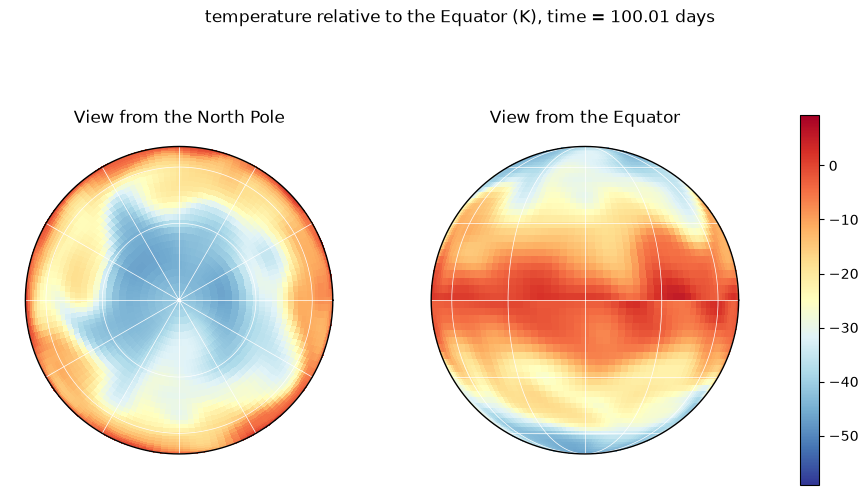

In [7]:
# Create a movie of the results

# Create a figure
fig = plt.figure(figsize=(12,6))

# Create arrays with the longitude and latitude of the corners of each grid cell (in radians) for plotting using pcolormesh
from dedalus.extras import plot_tools
(lon_mesh, lat_mesh) = plot_tools.quad_mesh(np.squeeze(phi), np.squeeze(lat))
lat_mesh = np.clip(lat_mesh, -np.pi/2, np.pi/2)

# Orthographic projection of the sphere, viewed from above the point (lon_c, lat_c)
# cos_c is negative for points on the far side of the sphere, which are hidden from view
def project(lon, lat, lon_c, lat_c):
    X = np.cos(lat)*np.sin(lon-lon_c)
    Y = np.cos(lat_c)*np.sin(lat) - np.sin(lat_c)*np.cos(lat)*np.cos(lon-lon_c)
    cos_c = np.sin(lat_c)*np.sin(lat) + np.cos(lat_c)*np.cos(lat)*np.cos(lon-lon_c)
    return X, Y, cos_c

# Set up the two views: from above the North Pole (left) and from above the Equator (right)
views = []
for (lon_c, lat_c, title) in [(0, np.pi/2, 'View from the North Pole'), (0, 0, 'View from the Equator')]:
    X, Y, cos_c = project(lon_mesh, lat_mesh, lon_c, lat_c)
    hidden = project(phi.T, lat.T, lon_c, lat_c)[2] < 0 # Grid cells on the far side of the sphere
    views.append((lon_c, lat_c, title, X, Y, hidden))

# Draw lines of latitude and longitude every 30 degrees
def draw_gridlines(lon_c, lat_c):
    lon_line = np.linspace(0, 2*np.pi, 361)
    lat_line = np.linspace(-np.pi/2, np.pi/2, 181)
    for lat_g in np.arange(-60, 61, 30)*np.pi/180:
        Xg, Yg, cos_c = project(lon_line, lat_g, lon_c, lat_c)
        plt.plot(np.where(cos_c >= 0, Xg, np.nan), Yg, color='w', lw=0.5)
    for lon_g in np.arange(0, 360, 30)*np.pi/180:
        Xg, Yg, cos_c = project(lon_g, lat_line, lon_c, lat_c)
        plt.plot(np.where(cos_c >= 0, Xg, np.nan), Yg, color='w', lw=0.5)
    plt.plot(np.cos(lon_line), np.sin(lon_line), color='k', lw=1) # Outline of the sphere

# Calculate the temperature (relative to the Equator) from the difference between the streamfunctions using thermal wind balance
# f changes sign at the Equator, so the relationship between temperature and psi1-psi2 does too
T_save = np.sign(lat)*(f0*T0/(g*H))*(psi1_save - psi2_save)
Tmin = T_save[1:].min()
Tmax = T_save[1:].max()

# Define an animation function
def drawframe(n):
    plt.clf()
    temperature = T_save[n,:,:].T
    axes = []
    for i, (lon_c, lat_c, title, X, Y, hidden) in enumerate(views):
        axes.append(plt.subplot(1, 2, i+1))
        temp = plt.pcolormesh(X, Y, np.ma.masked_where(hidden, temperature), vmin=Tmin, vmax=Tmax, cmap='RdYlBu_r')
        draw_gridlines(lon_c, lat_c)
        plt.gca().set_aspect('equal')
        plt.axis('off')
        plt.title(title)
    plt.colorbar(temp, ax=axes, shrink=0.8)
    plt.suptitle('temperature relative to the Equator (K), time = {0:.2f} days'.format(t_save[n]/3600/24))
    return (temp,)

import matplotlib as mpl
mpl.rcParams['animation.ffmpeg_path'] = '/home/ealish/miniforge3/bin/ffmpeg'
from matplotlib import animation
# blit=True re-draws only the parts that have changed.
# Skip the first frame (time=0), since the streamfunctions are only calculated after the first timestep
anim = animation.FuncAnimation(fig, drawframe, frames=range(1, len(t_save)), interval=40, blit=True)

from IPython.display import HTML
HTML(anim.to_html5_video())

### 3.2 Student investigation
<a id='section3pt2'></a>

Start with a control run with $\Delta T = 60$ K. Make a movie of the upper layer wind speed (you can use the code from Section 2.2) and describe the spin-up and the statistically steady state. Then, plot the time-averaged, zonally-averaged velocity in each layer (`u1_save` and `u2_save`) as a function of latitude, averaging over the last 50 days. Where are the jets, and how do they compare with the jets that you imposed in Section 2? Why do you think the lower layer velocity is non-zero?

Next, explore how the jets and storms respond to climate change by varying $\Delta T$ above and below the control value (for example, $\Delta T$ = 30, 40, 50, 70 and 80 K). Reducing $\Delta T$ represents a climate in which polar amplification wins, and increasing $\Delta T$ represents a climate in which the faster warming of the tropical upper troposphere wins. For each case, measure the latitude and speed of the jets and the strength of the storms. You can measure the storm activity using the eddy kinetic energy, $\frac{1}{2}(u'^2+v'^2)$, where $u'$ and $v'$ are departures from the zonal average (for example, `u1_save - np.mean(u1_save, axis=1, keepdims=True)`). How do the jets and the storms respond when $\Delta T$ is reduced, and when it is increased? Use the criterion for baroclinic instability from lectures to help explain your results.

Finally, comment on the limitations of this model. For example, reducing $\Delta T$ reduces the temperature gradient by the same fraction at all latitudes, while polar amplification in the real atmosphere is concentrated at high latitudes. In the 2-layer model $T$ represents the temperature in the middle of the troposphere, so the model cannot represent the temperature difference decreasing near the surface and increasing in the upper troposphere at the same time. The model also has no moisture, so it cannot represent the increase in precipitation in storms, or the extra latent heat that they release, as the climate warms. How might these limitations affect your conclusions?

In [ ]:
# Add code here to calcluat and plot the eddy kinetic energy or another measure of the storm strength.

INSERT COMMENTS HERE (1-2 PARAGRAPHS)